# Payment Investigation NLP — message classification on BANKING77

**Problem.** Payment and banking support teams manually read every incoming
customer message and route it to the right queue (card arrival, lost card,
refund not showing, identity verification, ...). Manual triage is slow,
inconsistent, and it delays exactly the cases — fraud, duplicate charges,
failed transfers — where speed matters.

**Approach.** Train an intent classifier on **BANKING77** (13,083 real
customer queries, 77 intents) and compare a TF-IDF baseline against an
advanced model. On top of the label, a rule-based extractor pulls the
amount, date, card last-4 and transaction/reference IDs out of the message —
the fields an investigator needs before they can act.

All 77 intents are kept (no grouping): each intent maps to a distinct
resolution queue, and grouping would hide the confusions that matter.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # repo root, for `src` imports

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data import load_banking77, intent_names, TEXT_COL, LABEL_COL

sns.set_theme(style="whitegrid")
train_df, test_df = load_banking77()
labels = intent_names(train_df)
print(f"train: {len(train_df):,}  test: {len(test_df):,}  intents: {len(labels)}")
train_df.head(3)

/home/hatch/workspace/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: 10,003  test: 3,080  intents: 77


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival


BANKING77 is close to balanced for a real support dataset: a **median of 127
training examples per intent** (range 35–187), and exactly **40 test examples
per intent** — so accuracy and macro-F1 track each other closely, and no
intent dominates the headline numbers.

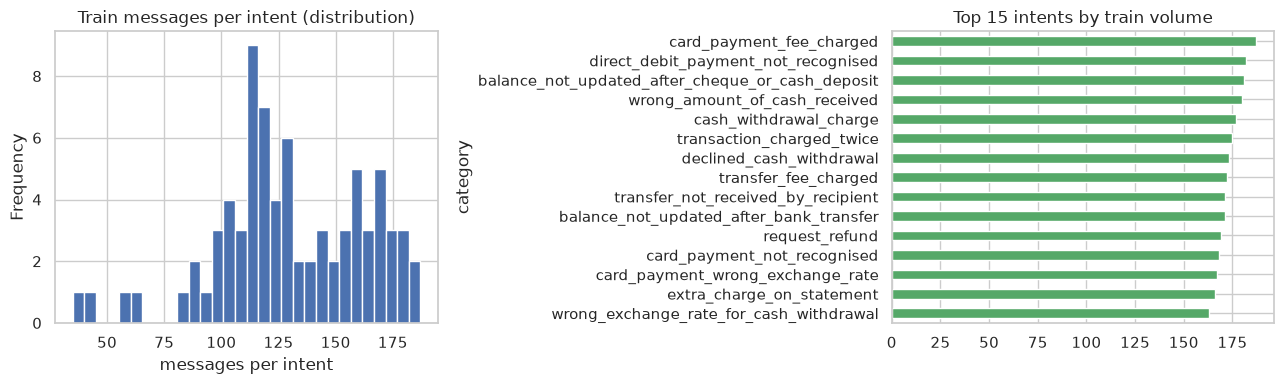

min 35 / median 127 / max 187 messages per intent


In [2]:
counts = train_df[LABEL_COL].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts.plot(kind="hist", bins=30, ax=axes[0], color="#4C72B0")
axes[0].set_title("Train messages per intent (distribution)")
axes[0].set_xlabel("messages per intent")
counts.head(15).plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].invert_yaxis()
axes[1].set_title("Top 15 intents by train volume")
plt.tight_layout()
plt.show()
print(f"min {counts.min()} / median {int(counts.median())} / max {counts.max()} messages per intent")

## 2. Train both models

- **Baseline** — TF-IDF word n-grams (1–2) + Logistic Regression.
- **Advanced** — **sentence-transformer embeddings** (`all-MiniLM-L6-v2`,
  384-dim) + Logistic Regression on the frozen embeddings. Semantic
  embeddings generalise beyond memorised wording, which matters because
  customers paraphrase the same problem endlessly. (If
  `sentence-transformers`/torch is unavailable, `src/embeddings_model.py`
  falls back to TF-IDF word+char n-grams and records that in
  `reports/metrics.json` — the backend that actually ran is printed below.)

In [3]:
from src.baseline import build_baseline
from src.embeddings_model import build_advanced
from src.evaluate import classification_summary, most_confused_pairs

X_train, y_train = train_df[TEXT_COL], train_df[LABEL_COL]
X_test, y_test = test_df[TEXT_COL], test_df[LABEL_COL]

baseline = build_baseline().fit(X_train, y_train)
advanced, backend = build_advanced()
print("advanced backend:", backend)
advanced = advanced.fit(X_train, y_train)

rows = {}
for name, model in [("TF-IDF baseline", baseline), ("Advanced", advanced)]:
    pred = model.predict(X_test)
    rows[name] = classification_summary(y_test, pred)
    print(name, {k: round(v, 4) for k, v in rows[name].items()})
pd.DataFrame(rows).T

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6191.88it/s]

advanced backend: sentence-transformers:sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8613.91it/s]

TF-IDF baseline {'accuracy': 0.8938, 'macro_f1': 0.8942, 'weighted_f1': 0.8942}


Advanced {'accuracy': 0.9299, 'macro_f1': 0.9298, 'weighted_f1': 0.9298}


,accuracy,macro_f1,weighted_f1
TF-IDF baseline,0.893831,0.894189,0.894189
Advanced,0.929870,0.929757,0.929757


## 3. Where do the models get confused?

The most-confused (true → predicted) pairs are operationally interesting:
they are intent pairs whose *situations genuinely overlap* — with the
embeddings model the residual errors concentrate in the **transfer-status
cluster** (`balance_not_updated_after_bank_transfer`,
`pending_transfer`, `transfer_not_received_by_recipient` — different stages
of the same journey, described in nearly identical words), with the classic
identity-verification cluster close behind.

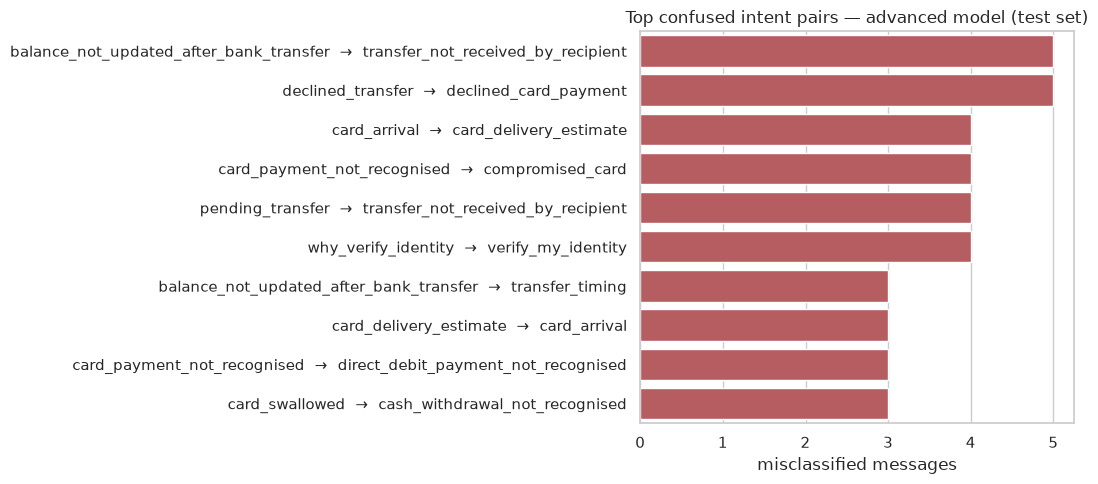

,true_intent,predicted_intent,count
0,balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient,5
1,declined_transfer,declined_card_payment,5
2,card_arrival,card_delivery_estimate,4
3,card_payment_not_recognised,compromised_card,4
4,pending_transfer,transfer_not_received_by_recipient,4
5,why_verify_identity,verify_my_identity,4
6,balance_not_updated_after_bank_transfer,transfer_timing,3
7,card_delivery_estimate,card_arrival,3
8,card_payment_not_recognised,direct_debit_payment_not_recognised,3
9,card_swallowed,cash_withdrawal_not_recognised,3


In [4]:
pairs = most_confused_pairs(y_test, advanced.predict(X_test), labels, top_k=10)
pairs_df = pd.DataFrame(pairs)
pairs_df["pair"] = pairs_df["true_intent"] + "  →  " + pairs_df["predicted_intent"]
plt.figure(figsize=(11, 5))
sns.barplot(data=pairs_df, y="pair", x="count", color="#C44E52")
plt.title("Top confused intent pairs — advanced model (test set)")
plt.xlabel("misclassified messages")
plt.ylabel("")
plt.tight_layout()
plt.show()
pairs_df.drop(columns="pair")

## 4. Example predictions with entity extraction

`predict_message` returns the intent, a calibrated confidence, the top-3
candidate queues, and the structured entities. Low-confidence predictions
are exactly the ones a production router would send to a human — the top-3
list gives that human a head start.

In [5]:
from src.predict import predict_message

examples = [
    "I was charged $59.99 twice on March 3 for the same order, card ending in 4321, txn TXN-8F3K2X9",
    "My new card still hasn't arrived after two weeks, where is it?",
    "The transfer I sent on 2026-03-14 still hasn't reached my brother",
    "Someone stole my wallet and my card was in it, please block it",
]
for msg in examples:
    out = predict_message(baseline, msg)
    print(f"MSG: {msg}")
    print(f"  -> {out['intent']} (confidence {out['confidence']:.2f})")
    print(f"     entities: {out['entities']}")


MSG: I was charged $59.99 twice on March 3 for the same order, card ending in 4321, txn TXN-8F3K2X9
  -> transaction_charged_twice (confidence 0.97)
     entities: {'amounts': [{'raw': '$59.99', 'value': 59.99}], 'dates': ['March 3'], 'card_last4': ['4321'], 'transaction_ids': ['TXN-8F3K2X9']}
MSG: My new card still hasn't arrived after two weeks, where is it?
  -> card_arrival (confidence 0.99)
     entities: {'amounts': [], 'dates': [], 'card_last4': [], 'transaction_ids': []}
MSG: The transfer I sent on 2026-03-14 still hasn't reached my brother
  -> transfer_not_received_by_recipient (confidence 0.58)
     entities: {'amounts': [], 'dates': ['2026-03-14'], 'card_last4': [], 'transaction_ids': []}
MSG: Someone stole my wallet and my card was in it, please block it
  -> lost_or_stolen_card (confidence 0.53)
     entities: {'amounts': [], 'dates': [], 'card_last4': [], 'transaction_ids': []}


## 5. Error analysis

A sample of the advanced model's test-set mistakes. Most are *defensible*
errors — wording that genuinely straddles two queues — which is why a
production deployment should route by confidence threshold, not by argmax
alone: high-confidence traffic goes straight to the queue, the ambiguous
remainder goes to a human with the top-3 suggestions attached.

In [6]:
adv_pred = advanced.predict(X_test)
errors = test_df.assign(predicted=adv_pred)
errors = errors[errors[LABEL_COL] != errors["predicted"]]
print(f"advanced model errors: {len(errors)} / {len(test_df)} ({len(errors)/len(test_df):.1%})")
errors.head(8)[[TEXT_COL, LABEL_COL, "predicted"]].rename(
    columns={LABEL_COL: "true_intent"})

advanced model errors: 216 / 3080 (7.0%)


,text,true_intent,predicted
0,How do I locate my card?,card_arrival,lost_or_stolen_card
5,When will I get my card?,card_arrival,card_delivery_estimate
11,How long does a card delivery take?,card_arrival,card_delivery_estimate
22,How long should my new card take to arrive?,card_arrival,card_delivery_estimate
32,How do I know when my card will arrive?,card_arrival,card_delivery_estimate
93,Is it a good time to exchange?,exchange_rate,transfer_not_received_by_recipient
121,I made a currency exchange and think I was cha...,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal
138,Why am I being charged more ?,card_payment_wrong_exchange_rate,card_payment_fee_charged


## Takeaways

1. A TF-IDF + Logistic Regression baseline is already strong on short
   support queries (~89% accuracy) — always build it before reaching for
   heavier machinery.
2. Sentence embeddings add **+3.6 points of accuracy and macro-F1**
   (0.930 vs 0.894 on this test set): encoding *meaning* beats matching
   *wording* when customers paraphrase.
3. The residual errors concentrate in semantically adjacent intent clusters
   (transfer status, identity verification, card-not-working). Those are
   taxonomy problems as much as modelling problems — and the fix is
   confidence-thresholded human review, not just a bigger model.